# Direct encoder weight editing with a frozen classifier

An additional experiment in tool-assisted weight-space programming. Codex acted as the editor in the chat: it inspected failures, rationales and internal diagnostics, then chose and wrote each of four patches after seeing preceding feedback. The classifier head stayed bitwise unchanged. No optimizer, gradients, regression solve or automatic parameter search was used during repair.

**This notebook replays the recorded decisions.** It does not call an editor LLM or claim autonomous rediscovery. The original model was already fine-tuned with gradients; the no-gradient restriction applies to this repair stage.

Measured result: **fresh hard-test accuracy 1/24 → 15/24**, ordinary test **8/8 → 8/8**, train **24/24 → 23/24**. The selected edit changes **6,912 positional-embedding values** and depends on the original header layout. This is not evidence of general negation reasoning, and positional-embedding edits differ from the paper's Experiment 8 restrictions.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image, Code
ROOT = Path.cwd()
assert (ROOT / 'direct_weight_editing/session.py').exists(), 'Launch from the repository root.'
HERE = ROOT / 'direct_weight_editing'
REPLAY_RECORDED_EDITS = False
REPORT = HERE / 'results'


## 1. Protocol and feedback boundary

Only the 24 original train examples and eight hard-repair examples (plus their request-only variants) supplied model feedback during editing. The new 24-case hard set and 12-case varied-format stress set were frozen before diagnostics and first evaluated after selection. They were authored by the same agent, so this is a procedural holdout rather than independent or blinded evaluation. The original tests were previously seen.

A maximum of four nonbaseline patches was allowed. Accept candidates retaining at least 23/24 train examples. Select by repair accuracy, train accuracy, then fewer changed values and earlier candidate. All candidates, including failed interventions, are retained.

In [2]:
display(Markdown((HERE / 'PROTOCOL.md').read_text()))
original = pd.read_json(ROOT / 'data/tickets.json')
display(original[original['split']=='hard_repair'][['id','request','label_name']])

# Direct encoder weight editing with a frozen classifier

This follow-up uses the saved baseline from the original experiment. No initial retraining is needed. During repair, every parameter has requires_grad=False and torch gradient recording is disabled. The classifier head is bitwise frozen. Forward architecture, attention masks, tokenization, pooling and classification logic stay fixed. Only explicit encoder tensor replacements are allowed. No optimizer, backward pass, closed-form residual fitting, automated numeric parameter search or regression solve is permitted during repair.

The editor is Codex in the current interactive chat. It reads diagnostic results, chooses a specific edit, executes it, and records a short decision summary. There is no separate editor API or claim that a fixed replay script autonomously discovers the edit. The extra notebook replays the chosen sequence and shows the recorded evidence. These are human-readable decision summaries, not a hidden reasoning trace.

Feedback: original train (24) and original hard_repair (8), plus eight current-request-only variants of the repair examples for diagnosis. Correct labels and concise authored rationales are supplied for repair. Ordinary test (8), old hard test (10), new hard test (24) and format-stress test (12) are final evaluation only. The old tests are previously seen and cannot be considered fresh evidence. New tests are authored in advance by the same agent: procedural holdout, not independent authorship or blinding. No descendants of new test examples are allowed in diagnosis.

Budget: at most four nonbaseline candidate patches and eight additional diagnostic reports. Small batches on Apple MPS when available. Pure CPU tensor inspection/edit construction and metrics are permitted. Candidate acceptance: train accuracy >= 23/24; select highest repair accuracy, then train accuracy, then smallest changed-scalar count, then earliest candidate. No-edit is included. All candidates and regressions must be reported. If no candidate improves repair subject to retention, select no edit.

Edits may target embeddings, positional embeddings, attention or FFN weights. Any edit that relies on a fixed input layout must be described as a positional/format-specific intervention, and reported separately on varied-format stress cases. Never claim acquisition of general reasoning from this benchmark.

Finalize selection before opening final-test predictions. Save the selected exact tensor patch, weight and head hashes, all feedback and editor decisions. Report all original metrics plus fresh hard/format-stress metrics, per-example predictions, Wilson accuracy intervals, changed parameters and elapsed time. Existing notebook/results must remain intact.


,id,request,label_name
32,hard_repair_00,My login works and no password reset is needed...,billing
33,hard_repair_01,The invoice is correct and no refund is needed...,account_access
34,hard_repair_02,Access has been restored; the unresolved issue...,billing
35,hard_repair_03,The duplicate debit has been reversed; the unr...,account_access
36,hard_repair_04,Do not unlock anything. Please cancel the paid...,billing
37,hard_repair_05,Do not cancel the paid plan. Please unlock my ...,account_access
38,hard_repair_06,I am already signed in. The charge for a cance...,billing
39,hard_repair_07,I received the reimbursement. The account reco...,account_access


## 2. Replay without altering the published result files

The default is to view the recorded run. Set `REPLAY_RECORDED_EDITS=True` and Run All to replay the saved sequence using your existing baseline. This makes no new LLM calls. Each replay writes an isolated directory under `direct_weight_editing/runs/`, leaving the original notebook/results intact.

If `checkpoints/baseline.pt` is missing, first run `.venv/bin/python experiment.py` at the repository root. This initial baseline generation uses training; the subsequent encoder-repair replay does not. Different baseline weights or kernels can change measured results.

In [3]:
if REPLAY_RECORDED_EDITS:
    from direct_weight_editing.replay import run_replay
    REPORT = run_replay()
print('Displaying reports from:', REPORT.relative_to(ROOT))


Displaying reports from: direct_weight_editing/results


## 3. What the LLM inspected

The initial probe showed only **1/8** correct full-context repair cases and **3/8** request-only variants. Metadata is one problem; competing resolved and active intents are another.

Attention mass is a diagnostic clue rather than proof of causal importance. Inspecting high-attention heads led to a causal ablation test. Token positions also exposed a stable archived-header region, supporting a separate format-specific weight program.

In [4]:
inspection = json.loads((REPORT / 'inspection.json').read_text())
display(pd.DataFrame(inspection['examples']))
display(pd.DataFrame(inspection['attention_summary']))
display(pd.DataFrame([{'id':r['id'],'header_positions':r['header_positions'],'active_request_starts':r['active_start_position']} for r in inspection['token_layout']]))
display(pd.DataFrame(inspection['last_ffn_top_head_aligned_columns']))

,id,text,label,baseline_prediction,request_only_prediction,rationale
0,hard_repair_00,Archived routing metadata: Account access depa...,0,1,1,Route the unresolved current billing request; ...
1,hard_repair_01,Archived routing metadata: Billing department....,1,0,0,Route the unresolved current account-access re...
2,hard_repair_02,Archived routing metadata: Account access depa...,0,1,1,Route the unresolved current billing request; ...
3,hard_repair_03,Archived routing metadata: Billing department....,1,0,1,Route the unresolved current account-access re...
4,hard_repair_04,Archived routing metadata: Account access depa...,0,1,0,Route the unresolved current billing request; ...
5,hard_repair_05,Archived routing metadata: Billing department....,1,0,0,Route the unresolved current account-access re...
6,hard_repair_06,Archived routing metadata: Account access depa...,0,0,0,Route the unresolved current billing request; ...
7,hard_repair_07,Archived routing metadata: Billing department....,1,0,0,Route the unresolved current account-access re...


,layer,head,request_attention_to_header,request_attention_to_request
0,0,6,0.493575,0.352548
1,0,1,0.479464,0.373028
2,0,9,0.471257,0.315640
3,5,7,0.452744,0.369544
4,0,11,0.435837,0.403560
5,5,4,0.434341,0.369906
6,3,11,0.433253,0.409933
7,5,11,0.422685,0.300160
8,5,6,0.420806,0.350595
9,0,7,0.402314,0.399104


,id,header_positions,active_request_starts
0,hard_repair_00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",22
1,hard_repair_01,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",23


,column,abs_alignment
0,744,0.523916
1,143,0.382121
2,77,0.351069
3,265,0.335599
4,507,0.321528
5,475,0.319295
6,729,0.318358
7,1478,0.311045


In [5]:
display(json.loads((REPORT / 'embedding_weight_inspection.json').read_text()))
ffn = pd.read_csv(REPORT / 'ffn_diagnostic.csv')
display(ffn.groupby(['column','label'])[['signed_class0_write','header_activation','active_evidence_activation']].mean())

{'[CLS]': {'id': 101,
  'norm': 1.5457208156585693,
  'first_8_coordinates': [-0.01761939749121666,
   -0.007600549608469009,
   0.047105543315410614,
   -0.08691827207803726,
   -0.025449857115745544,
   -0.0013143301475793123,
   -0.013546222820878029,
   0.004580335225909948]},
 '[SEP]': {'id': 102,
  'norm': 1.057968020439148,
  'first_8_coordinates': [0.033166009932756424,
   -0.008535295724868774,
   -0.03998308628797531,
   0.009619301185011864,
   0.020369581878185272,
   0.012308887206017971,
   0.04437381774187088,
   0.007374027743935585]},
 'billing': {'id': 25640,
  'norm': 1.2564111948013306,
  'first_8_coordinates': [-0.00837808009237051,
   -0.0033857361413538456,
   0.04451629891991615,
   -0.05691950395703316,
   0.012224540114402771,
   -0.01481692772358656,
   0.060204919427633286,
   -0.06387518346309662]},
 'password': {'id': 20786,
  'norm': 1.3753221035003662,
  'first_8_coordinates': [-0.09577513486146927,
   0.10817399621009827,
   -0.019952815026044846,
   0.

signed_class0_write  header_activation  \
column label                                           
77     0                -0.351069           0.172904   
       1                -0.351069           0.094896   
143    0                -0.382121          -0.102584   
       1                -0.382121          -0.105832   
265    0                -0.335599          -0.143941   
       1                -0.335599          -0.131147   
475    0                 0.319295           0.043484   
       1                 0.319295           0.008042   
507    0                 0.321528          -0.043494   
       1                 0.321528          -0.101683   
729    0                -0.318358          -0.098434   
       1                -0.318358          -0.102196   
744    0                 0.523916          -0.055122   
       1                 0.523916          -0.136801   
1478   0                -0.311045           0.241047   
       1                -0.311045           0.107816   

              active_evidence_activation  
column label                              
77     0                        0.054295  
       1                        0.037428  
143    0                       -0.100967  
       1                       -0.104010  
265    0                       -0.130755  
       1                       -0.132193  
475    0                        0.031538  
       1                       -0.046452  
507    0                       -0.096986  
       1                       -0.074760  
729    0                       -0.062230  
       1                       -0.088698  
744    0                       -0.115233  
       1                       -0.103722  
1478   0                        0.054740  
       1                        0.329432

## 4. The four recorded edits and their feedback

1. Disable the contribution of last-block attention head 7. Repair did not improve.
2. Replace positional rows 1..18 with `8 × pretrained SEP embedding`. This intends to attenuate header-token identity through embedding LayerNorm. Repair improves, but the edit relies on the header's location.
3. Disable last-FFN output column 77 after inspecting its activation/write statistics. Repair did not improve. Statistics alone do not prove a semantic feature.
4. Combine the positional edit with disabling early head 0.6. It tied the positional candidate on development counts while changing more values, so the smaller edit wins.

Every patch is a direct assignment to an encoder tensor. No classifier parameter is assigned. The fixed model architecture, tokenization, attention mask and mean pooling are unchanged.

In [6]:
history = json.loads((REPORT / 'candidate_log.json').read_text())
columns = ['candidate','train_correct','train_n','hard_repair_correct','hard_repair_n','repair_request_only_correct','changed_scalars','eligible','head_unchanged']
display(pd.DataFrame(history)[columns])
for record in history:
    display(Markdown('**' + record['candidate'] + '**: ' + record['explanation']))

,candidate,train_correct,train_n,hard_repair_correct,hard_repair_n,repair_request_only_correct,changed_scalars,eligible,head_unchanged
0,no_edit,24,24,1,8,3,0,True,True
1,attention_head_5_7_off,24,24,1,8,3,12288,True,True
2,header_position_neutralization,23,24,3,8,4,6912,True,True
3,ffn_column_77_off,24,24,1,8,3,384,True,True
4,position_plus_early_head_off,23,24,3,8,4,19200,True,True


**no_edit**: Baseline: inspect errors before making any tensor change.

**attention_head_5_7_off**: Inspection showed last-block head 7 allocates 45.3% of request attention to the archived header on two repair probes. Test its causal contribution by zeroing only its 32 output-projection columns. Attention mass alone does not establish causality; measure repair and train retention.

**header_position_neutralization**: Head 5.7 ablation did not improve repair. The rationales say archived metadata is irrelevant. Token inspection places that header at positions 1..18 in this schema. Replace those positional rows with 8 times the pretrained SEP embedding (norm about 8.46 versus ordinary token norms about 1.3), intending to attenuate header-token identity through embedding LayerNorm. Forward code and masks stay fixed. This is a format-specific weight program and may damage inputs whose requests occur earlier; assess that limitation on format stress.

**ffn_column_77_off**: FFN diagnostic: column 77 writes toward account access (signed billing-minus-access alignment -0.3511). Its mean header activation is 0.1729 on true-billing repair cases versus 0.0543 on their active evidence, suggesting a possible archived-access contribution. Disable only that column. Do not disable column 1478, whose activation is also much higher on genuine active access evidence. These are attribution hypotheses tested by intervention, not proven feature identities.

**position_plus_early_head_off**: Position neutralization improved repair from 1/8 to 3/8 with 23/24 train retained; the isolated FFN edit did not help. For the final budgeted candidate, combine the positional patch with disabling early attention head 0.6, which had the highest request-to-header attention in the diagnostic (49.4%). This tests whether an early header-focused pathway continues to carry misleading information after input neutralization. No further candidates after final evaluation.

### Exact tensor-edit code

These functions were authored sequentially during the interactive editing session. The saved replay runs them in the same order. Constants are recorded choices, not a parameter sweep.

In [7]:
display(Code((HERE / 'editor_steps.py').read_text(), language='python'))

"""Explicit patches authored by Codex after reading each preceding diagnostic result.

This file replays decisions. It is not an automated editor or parameter search.
Every patch starts from the same saved baseline unless stated otherwise.
"""
import torch
from .session import Session

def step_1(s:Session):
 s.load_patch('no_edit')
 # Layer 5, head 7: highest archived-header attention among the last-block heads.
 # Head size 32; zero only this head's contribution through the output projection.
 key='encoder.encoder.layer.5.attention.output.dense.weight'
 weight=s.model.state_dict()[key]
 weight[:,7*32:8*32]=0
 return s.assess('attention_head_5_7_off',
  'Inspection showed last-block head 7 allocates 45.3% of request attention to the archived header on two repair probes. Test its causal contribution by zeroing only its 32 output-projection columns. Attention mass alone does not establish causality; measure repair and train retention.')

STEPS=[step_1]

def step_2(s:Session):
 s.load_patch('no_edit')
 # A format-specific experiment, not a general learned rationale mechanism.
 # The two observed archived headers occupy positions 1..17 or 1..18;
 # actual request text begins at 22 or 23. CLS remains untouched.
 key='encoder.embeddings.position_embeddings.weight'
 sep=s.baseline['encoder.embeddings.word_embeddings.weight'][s.tokenizer.sep_token_id]
 replacement=8.0*sep
 s.model.state_dict()[key][1:19]=replacement.to(s.model.state_dict()[key].device)
 return s.assess('header_position_neutralization',
  'Head 5.7 ablation did not improve repair. The rationales say archived metadata is irrelevant. Token inspection places that header at positions 1..18 in this schema. Replace those positional rows with 8 times the pretrained SEP embedding (norm about 8.46 versus ordinary token norms about 1.3), intending to attenuate header-token identity through embedding LayerNorm. Forward code and masks stay fixed. This is a format-specific weight program and may damage inputs whose requests occur earlier; assess that limitation on format stress.')

STEPS.append(step_2)

def step_3(s:Session):
 s.load_patch('no_edit')
 key='encoder.encoder.layer.5.output.dense.weight'
 s.model.state_dict()[key][:,77]=0
 return s.assess('ffn_column_77_off',
  'FFN diagnostic: column 77 writes toward account access (signed billing-minus-access alignment -0.3511). Its mean header activation is 0.1729 on true-billing repair cases versus 0.0543 on their active evidence, suggesting a possible archived-access contribution. Disable only that column. Do not disable column 1478, whose activation is also much higher on genuine active access evidence. These are attribution hypotheses tested by intervention, not proven feature identities.')

STEPS.append(step_3)

def step_4(s:Session):
 s.load_patch('header_position_neutralization')
 key='encoder.encoder.layer.0.attention.output.dense.weight'
 s.model.state_dict()[key][:,6*32:7*32]=0
 return s.assess('position_plus_early_head_off',
  'Position neutralization improved repair from 1/8 to 3/8 with 23/24 train retained; the isolated FFN edit did not help. For the final budgeted candidate, combine the positional patch with disabling early attention head 0.6, which had the highest request-to-header attention in the diagnostic (49.4%). This tests whether an early header-focused pathway continues to carry misleading information after input neutralization. No further candidates after final evaluation.')

STEPS.append(step_4)

### Constrained diagnostic and patch harness

The harness disables gradient recording and freezes every parameter. The exact classifier weight and bias hashes are checked on every assessment. It only evaluates development data during editing and rejects any saved patch containing a non-encoder tensor.

In [8]:
display(Code((HERE / 'session.py').read_text(), language='python'))

"""Constrained, inference-only harness for an interactive Codex weight editor."""
from pathlib import Path
import json, hashlib, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from transformers import AutoConfig, AutoModel, AutoTokenizer

ROOT=Path(__file__).resolve().parent.parent
HERE=Path(__file__).resolve().parent
RESULTS=HERE/'results'
PATCHES=ROOT/'checkpoints/direct_encoder'
DEVICE=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
BATCH=8; MAX_LENGTH=96

def digest(tensor):return hashlib.sha256(tensor.detach().cpu().contiguous().numpy().tobytes()).hexdigest()
def file_digest(path):return hashlib.sha256(path.read_bytes()).hexdigest()
def state_digest(state):
 h=hashlib.sha256()
 for key,tensor in sorted(state.items()):
  h.update(key.encode());h.update(tensor.contiguous().numpy().tobytes())
 return h.hexdigest()

def wilson(correct,n):
 z=1.959963984540054;p=correct/n;den=1+z*z/n
 a=(p+z*z/(2*n))/den;b=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
 return a-b,a+b

class Model(nn.Module):
 def __init__(self):
  super().__init__()
  self.encoder=AutoModel.from_config(AutoConfig.from_pretrained(ROOT/'checkpoints'),attn_implementation='eager')
  self.head=nn.Linear(384,2)
 def forward(self,tokens):
  h=self.encoder(**tokens).last_hidden_state
  mask=tokens['attention_mask'].unsqueeze(-1)
  feature=nn.functional.normalize((h*mask).sum(1)/mask.sum(1).clamp_min(1),dim=-1)
  return self.head(feature)

class Session:
 def __init__(self):
  self.started=time.perf_counter()
  torch.set_grad_enabled(False);torch.set_num_threads(4)
  RESULTS.mkdir(exist_ok=True);PATCHES.mkdir(parents=True,exist_ok=True)
  self.baseline=torch.load(ROOT/'checkpoints/baseline.pt',weights_only=True,map_location='cpu')
  self.model=Model().to(DEVICE);self.model.load_state_dict(self.baseline);self.model.eval()
  for p in self.model.parameters():p.requires_grad_(False)
  self.tokenizer=AutoTokenizer.from_pretrained(ROOT/'checkpoints/tokenizer')
  self.data=pd.read_json(ROOT/'data/tickets.json')
  self.train=self.data[self.data.split=='train'].copy()
  self.repair=self.data[self.data.split=='hard_repair'].copy()
  # Current-request-only probes are variants of repair examples, never of final holdout examples.
  self.request_only=self.repair.copy();self.request_only['text']=self.request_only['request'];self.request_only['split']='repair_request_only'
  self.dev=pd.concat([self.train,self.repair,self.request_only],ignore_index=True)
  self.head_hash={k:digest(v) for k,v in self.baseline.items() if k.startswith('head.')}
 def tokenize(self,texts):
  return {k:v.to(DEVICE) for k,v in self.tokenizer(list(texts),padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors='pt').items()}
 def predict(self,texts):
  self.model.eval()
  with torch.inference_mode():
   return np.concatenate([self.model(self.tokenize(texts[i:i+BATCH])).softmax(-1).cpu().numpy() for i in range(0,len(texts),BATCH)])
 def load_patch(self,name):
  self.model.load_state_dict(self.baseline)
  if name!='no_edit':
   patch=torch.load(PATCHES/f'{name}.pt',weights_only=True,map_location='cpu')
   assert all(k.startswith('encoder.') for k in patch)
   self.model.load_state_dict(patch,strict=False)
  self.assert_frozen_head()
 def assert_frozen_head(self):
  state=self.model.state_dict()
  assert all(digest(state[k])==v for k,v in self.head_hash.items())
  assert not any(p.requires_grad for p in self.model.parameters())
  assert not torch.is_grad_enabled()
 def assess(self,name,explanation):
  self.assert_frozen_head()
  probs=self.predict(self.dev.text.tolist())
  prediction=self.dev[['id','split','label','text']].copy()
  prediction['predicted']=probs.argmax(1);prediction['p_billing']=probs[:,0];prediction['p_account_access']=probs[:,1]
  prediction['correct']=prediction.predicted==prediction.label
  prediction.to_csv(RESULTS/f'dev_{name}.csv',index=False)
  patch={k:v.detach().cpu().clone() for k,v in self.model.state_dict().items() if not torch.equal

## 5. Selection fixed before final evaluation

The saved selection binds the development log, baseline and holdout hashes. No final-test prediction is used in the selection rule. All final results below are retained without further edits.

In [9]:
selection = json.loads((REPORT / 'final_selection.json').read_text())
display(selection)
display(pd.read_csv(REPORT / 'weight_changes.csv'))

{'selected_candidate': 'header_position_neutralization',
 'selection_rule': 'repair accuracy, train accuracy, fewest changed scalars, earliest; train >=23/24',
 'selected_record': {'candidate': 'header_position_neutralization',
  'explanation': 'Head 5.7 ablation did not improve repair. The rationales say archived metadata is irrelevant. Token inspection places that header at positions 1..18 in this schema. Replace those positional rows with 8 times the pretrained SEP embedding (norm about 8.46 versus ordinary token norms about 1.3), intending to attenuate header-token identity through embedding LayerNorm. Forward code and masks stay fixed. This is a format-specific weight program and may damage inputs whose requests occur earlier; assess that limitation on format stress.',
  'device': 'mps',
  'head_unchanged': True,
  'changed_scalars': 6912,
  'changed_tensors': ['encoder.embeddings.position_embeddings.weight'],
  'tensor_hashes': {'encoder.embeddings.position_embeddings.weight': 'f

,tensor,changed_scalars,before_sha256,after_sha256,delta_frobenius
0,encoder.embeddings.position_embeddings.weight,6912,4c347d866c9012e7160b42a7e36d9138935e0669cc6293...,f4cc71b046ef433b2bca9a0145554669f691bdff8cbf6c...,35.434483


## 6. Final accuracy and all classification metrics

The new hard set follows the original header schema. A separate format-stress set varies header length/order and includes requests without headers. Both are small synthetic sets, written by the same agent, with shared construction patterns.

Wilson intervals describe finite example count only. They do not account for shared templates, seed variability or design choices. Probability metrics are uncalibrated. Exact paired McNemar results are exploratory and unadjusted for multiple comparisons.

split,train,hard_repair,ordinary_test,old_hard_test,fresh_hard_test,format_stress_test
method,,,,,,
baseline,100.0%,12.5%,100.0%,0.0%,4.2%,33.3%
llm_encoder_edit,95.8%,37.5%,100.0%,70.0%,62.5%,66.7%


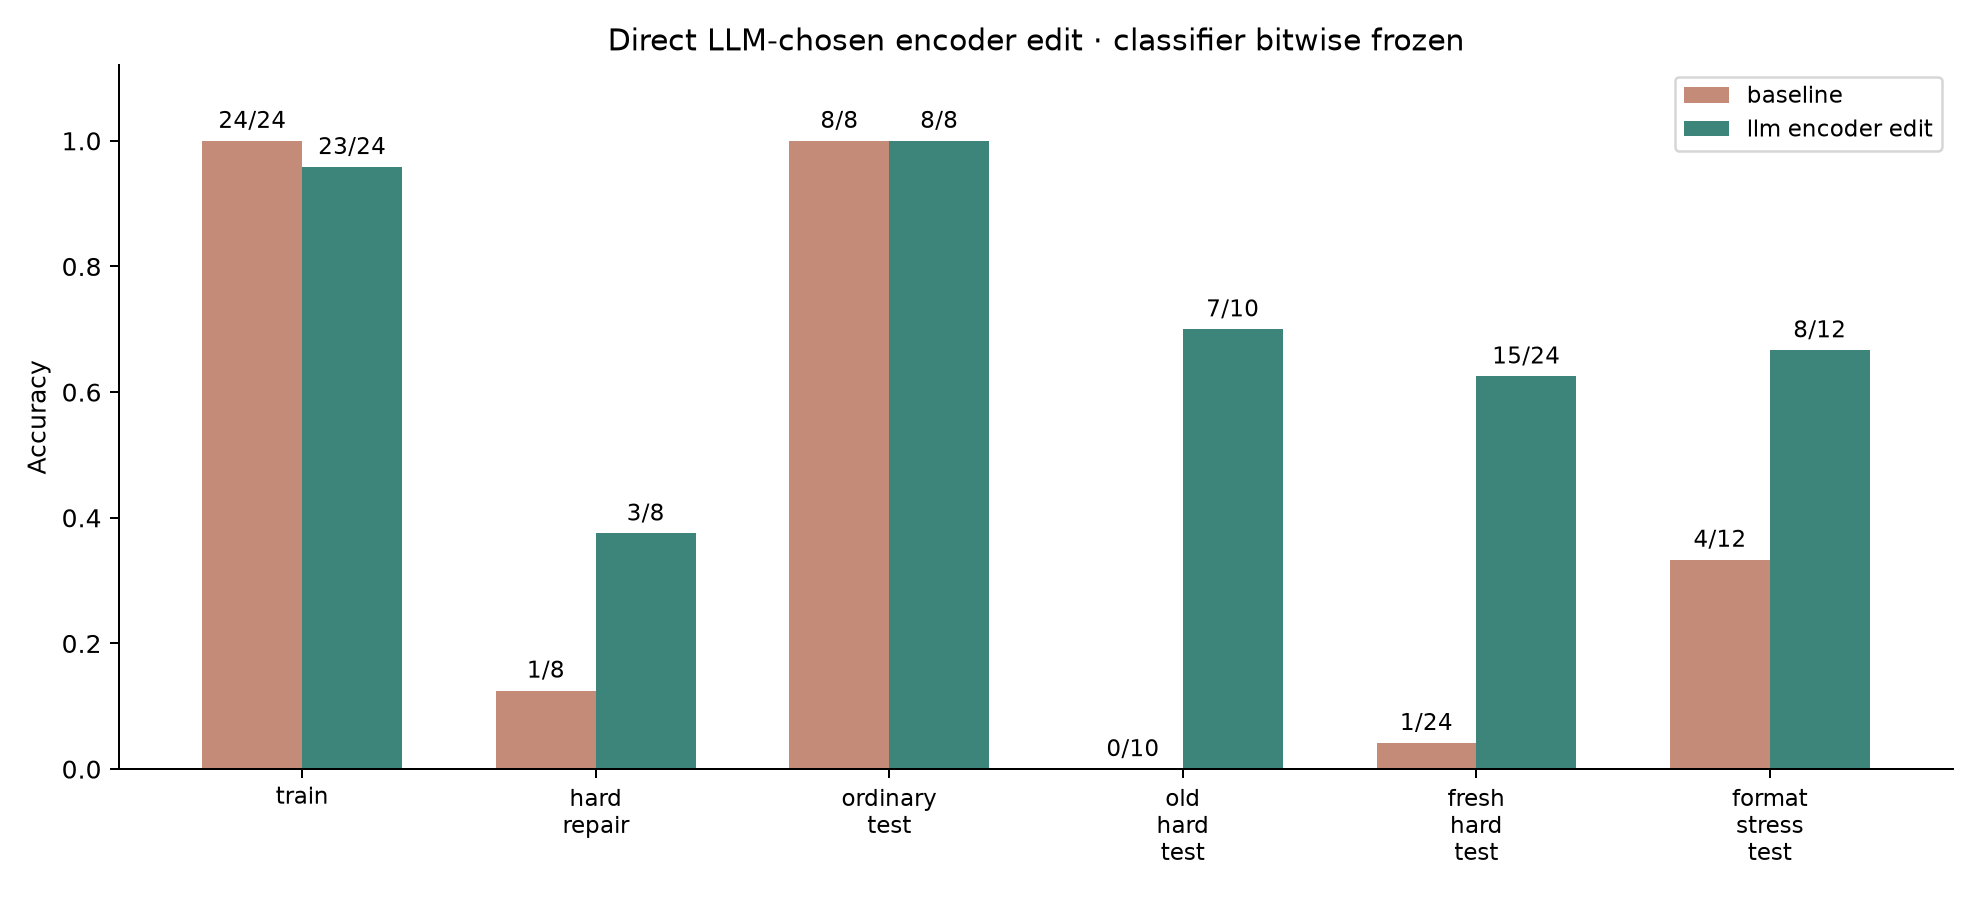

,4,5,10,11
method,baseline,baseline,llm_encoder_edit,llm_encoder_edit
split,fresh_hard_test,format_stress_test,fresh_hard_test,format_stress_test
n,24,12,24,12
correct,1,4,15,8
accuracy,0.041667,0.333333,0.625,0.666667
accuracy_ci95_low,0.007393,0.13812,0.4271,0.390622
accuracy_ci95_high,0.202418,0.609378,0.788406,0.86188
balanced_accuracy,0.041667,0.333333,0.625,0.666667
mcc,-0.919866,-0.353553,0.27501,0.447214
roc_auc,0.027778,0.305556,0.604167,0.638889


,method,split,n,correct,accuracy,accuracy_ci95_low,accuracy_ci95_high,balanced_accuracy,mcc,roc_auc,...,f1_weighted,precision_billing,recall_billing,f1_billing,support_billing,precision_account_access,recall_account_access,f1_account_access,support_account_access,ece_10_bins
0,baseline,train,24,24,1.000000,0.862024,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,12,1.000000,1.000000,1.000000,12,0.235278
1,baseline,ordinary_test,8,8,1.000000,0.675592,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,4,1.000000,1.000000,1.000000,4,0.246370
2,baseline,hard_repair,8,1,0.125000,0.022417,0.470888,0.125000,-0.774597,0.062500,...,0.111111,0.200000,0.250000,0.222222,4,0.000000,0.000000,0.000000,4,0.488435
3,baseline,old_hard_test,10,0,0.000000,0.000000,0.277533,0.000000,-1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,5,0.000000,0.000000,0.000000,5,0.619679
4,baseline,fresh_hard_test,24,1,0.041667,0.007393,0.202418,0.041667,-0.919866,0.027778,...,0.040000,0.000000,0.000000,0.000000,12,0.076923,0.083333,0.080000,12,0.563660
5,baseline,format_stress_test,12,4,0.333333,0.138120,0.609378,0.333333,-0.353553,0.305556,...,0.314286,0.250000,0.166667,0.200000,6,0.375000,0.500000,0.428571,6,0.271125
6,llm_encoder_edit,train,24,23,0.958333,0.797582,0.992607,0.958333,0.919866,1.000000,...,0.958261,0.923077,1.000000,0.960000,12,1.000000,0.916667,0.956522,12,0.389065
7,llm_encoder_edit,ordinary_test,8,8,1.000000,0.675592,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,4,1.000000,1.000000,1.000000,4,0.433019
8,llm_encoder_edit,hard_repair,8,3,0.375000,0.136844,0.694258,0.375000,-0.258199,0.437500,...,0.365079,0.400000,0.500000,0.444444,4,0.333333,0.250000,0.285714,4,0.265777
9,llm_encoder_edit,old_hard_test,10,7,0.700000,0.396778,0.892209,0.700000,0.500000,0.480000,...,0.670330,0.625000,1.000000,0.769231,5,1.000000,0.400000,0.571429,5,0.167279


,split,fixed,broken,both_correct,both_wrong,exact_mcnemar_p
0,ordinary_test,0,0,8,0,1.000000
1,old_hard_test,7,0,0,3,0.015625
2,fresh_hard_test,14,0,1,9,0.000122
3,format_stress_test,7,3,1,1,0.343750


In [10]:
metrics = pd.read_csv(REPORT / 'metrics.csv')
order = ['train','hard_repair','ordinary_test','old_hard_test','fresh_hard_test','format_stress_test']
display(metrics.pivot(index='method',columns='split',values='accuracy')[order].style.format('{:.1%}'))
display(Image(filename=str(REPORT / 'accuracy_comparison.png')))
display(metrics[metrics['split'].isin(['fresh_hard_test','format_stress_test'])].T)
display(metrics)
display(pd.read_csv(REPORT / 'paired_comparisons.csv'))

## 7. Per-example outcomes, including regressions

A newly correct answer and a newly broken answer both matter. Inspect both final test groups rather than treating 15/24 as a general capability claim.

In [11]:
predictions = pd.read_csv(REPORT / 'predictions.csv')
display(predictions[predictions['split'].isin(['fresh_hard_test','format_stress_test'])][['method','id','split','text','label','predicted','p_billing','p_account_access','correct']])
display(Markdown('**Remaining selected-edit errors on the fresh hard set:**'))
display(predictions[(predictions['method']=='llm_encoder_edit') & (predictions['split']=='fresh_hard_test') & (~predictions['correct'])])

,method,id,split,text,label,predicted,p_billing,p_account_access,correct
50,baseline,fresh_00_0,fresh_hard_test,Archived routing metadata: Account access depa...,0,1,0.415995,0.584005,False
51,baseline,fresh_00_1,fresh_hard_test,Archived routing metadata: Billing department....,1,0,0.542702,0.457298,False
52,baseline,fresh_01_0,fresh_hard_test,Archived routing metadata: Account access depa...,0,1,0.321076,0.678924,False
53,baseline,fresh_01_1,fresh_hard_test,Archived routing metadata: Billing department....,1,0,0.662279,0.337721,False
54,baseline,fresh_02_0,fresh_hard_test,Archived routing metadata: Account access depa...,0,1,0.462435,0.537565,False
...,...,...,...,...,...,...,...,...,...
167,llm_encoder_edit,format_07,format_stress_test,"Routing history: invoicing, card charges, refu...",1,1,0.487146,0.512854,True
168,llm_encoder_edit,format_08,format_stress_test,"I can enter my account, receive verification c...",0,0,0.589869,0.410131,True
169,llm_encoder_edit,format_09,format_stress_test,"I have my receipt, the amount is correct and t...",1,1,0.485961,0.514039,True
170,llm_encoder_edit,format_10,format_stress_test,Customer current request: reverse the duplicat...,0,0,0.513780,0.486220,True


**Remaining selected-edit errors on the fresh hard set:**

,method,id,split,label,text,predicted,p_billing,p_account_access,correct
139,llm_encoder_edit,fresh_01_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.569456,0.430544,False
141,llm_encoder_edit,fresh_02_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.539709,0.460291,False
143,llm_encoder_edit,fresh_03_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.571585,0.428415,False
145,llm_encoder_edit,fresh_04_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.546190,0.453810,False
147,llm_encoder_edit,fresh_05_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.501392,0.498608,False
153,llm_encoder_edit,fresh_08_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.532971,0.467029,False
155,llm_encoder_edit,fresh_09_1,fresh_hard_test,1,Archived routing metadata: Billing department....,0,0.584911,0.415089,False
156,llm_encoder_edit,fresh_10_0,fresh_hard_test,0,Archived routing metadata: Account access depa...,1,0.494849,0.505151,False
158,llm_encoder_edit,fresh_11_0,fresh_hard_test,0,Archived routing metadata: Account access depa...,1,0.485193,0.514807,False


## 8. Frozen-head and exact patch verification

The original run's verifier reconstructs the model from the compact non-pickle patch and checks all 86 selected-edit probabilities against the saved predictions. It also verifies tensor hashes, changed-scalar count, all accuracy counts, and absence of optimizer/backward/regression-solve calls in repair code. Full checkpoints remain local and ignored; the compact patch is versioned.

In [12]:
display(json.loads((REPORT / 'verification.json').read_text()))
if (REPORT / 'artifact_checks.json').exists():
    display(json.loads((REPORT / 'artifact_checks.json').read_text()))
else:
    print('See verification.json for this replay; full original-run checks are in the published results directory.')

{'head_unchanged': True,
 'head_hashes': {'head.weight': 'acf2a511d5693a2d22b0027c8e87fd1edc45ecbaaf72174afc7ae2ad58ccb486',
  'head.bias': 'db18f7a12fc64f179650816270d295e315a7be9075cd928b6b74e00fb2296142'},
 'all_parameters_requires_grad_false': True,
 'gradient_recording_disabled': True,
 'only_encoder_tensors_changed': True,
 'changed_scalars': 6912,
 'total_parameters': 22713986,
 'recorded_candidate_runs': 5,
 'candidate_seconds_including_load_total': 9.879966458014678,
 'evaluation_seconds_including_load': 2.3403393749613315,
 'device': 'mps',
 'selection_precedes_final_evaluation': True,
 'baseline_sha256': '2267e4da104effaaca47134762761ff0b9966f8e443aef4d699743211357860a',
 'holdout_sha256': '98923372a62c58580ba4f13cf22434decf959dcdd3a0907a93212027e320b7f6'}

{'passed': True,
 'head_bitwise_unchanged': True,
 'compact_patch_replays_predictions': True,
 'replayed_predictions': 86,
 'max_probability_error': 0.0,
 'no_optimizer_backward_or_regression_solve_calls_in_repair_code': True,
 'all_accuracy_counts_verified': True,
 'dataset_baseline_and_selection_hashes_verified': True,
 'changed_scalar_count': 6912}

## 9. Interpretation and measured report

This provides a concrete example of an LLM choosing a useful, direct encoder tensor edit with a frozen classifier. The mechanism is a positional intervention that weakens the archived header, not a demonstrated general reasoning circuit. Several intuitively motivated head/neuron edits failed. Training accuracy regressed by one example.

The original head-fitting control and this frozen-head experiment answer different questions and should not be conflated. A larger, independently authored benchmark and repeated baselines are needed to establish broader gains.

In [13]:
report_path = REPORT / 'RESULTS.md' if (REPORT / 'RESULTS.md').exists() else HERE / 'RESULTS.md'
display(Markdown(report_path.read_text()))

# Direct encoder editing: measured results

Selected patch: `header_position_neutralization`. Classifier weight and bias are bitwise unchanged.

| Split | Baseline | LLM encoder edit |
|---|---:|---:|
| train | 24/24 (100.0%) | 23/24 (95.8%) |
| hard_repair | 1/8 (12.5%) | 3/8 (37.5%) |
| ordinary_test | 8/8 (100.0%) | 8/8 (100.0%) |
| old_hard_test | 0/10 (0.0%) | 7/10 (70.0%) |
| fresh_hard_test | 1/24 (4.2%) | 15/24 (62.5%) |
| format_stress_test | 4/12 (33.3%) | 8/12 (66.7%) |

Changed 6,912 / 22,713,986 scalar parameters. Four nonbaseline candidates; MPS device recorded as `mps`.

The selected positional intervention replaces rows 1..18 with eight times the pretrained SEP embedding. It attempts to weaken archived-header content through the embedding LayerNorm. It is format-specific weight programming; it does not establish general negation understanding. The varied-format stress split measures some consequences of this restriction. Tokenization, attention masks, pooling and the classifier are unchanged.

The editor was Codex acting interactively in the chat: it inspected diagnostic reports, then authored each next patch. The notebook replays this recorded sequence; it does not make independent editor-model calls or rediscover the edits. No optimizer, gradients, supervised residual fitting or automated numeric search is used during repair.

The new 24-case hard test and 12-case format stress set were frozen before diagnostics and scored only after selection. They were authored by the same agent and share construction patterns, so the holdout is procedural, not independently authored or blinded. The original ordinary and hard tests are previously seen. All final results are retained and no post-evaluation edits are selected.

This is a general weight-space programming adaptation, not a reproduction of the paper’s Experiment 8: it permits positional embedding edits, whereas that experiment restricted embedding edits. The original baseline was already gradient-trained; the no-gradient claim applies only to this repair stage.

Metrics include classification and probability metrics, Wilson intervals, confusion matrices and exploratory unadjusted exact paired McNemar tests. Single baseline seed and small synthetic tests limit conclusions. See `results/` for all predictions, candidates, diagnostics and hashes.

On format stress, the edit fixes seven baseline errors and breaks three previously correct answers (net +4/12). The training set also loses one correct answer. These regressions remain in the prediction records.


Reference: [Sparks of Weight-Space Programming](https://rikiyat.github.io/blog/weight-space-programming/) and [released Experiment 8 protocol](https://github.com/RikiyaT/lm_understand-logs/tree/main/exp8_math). This follow-up uses the general direct-edit idea, while permitting positional-embedding edits that differ from that experiment's tensor restrictions.